# PRCFX-DT++ Fusion — Standard Late Concatenation (with Validation Set)

Late-fusion classifier for 30 virus classes. The Stream A CNN embedding and the Stream B PageRank vector are concatenated and classified by a small MLP.

## Setup

| Aspect | Setting |
|---|---|
| Data splits | 70 % train / 10 % val / 20 % test |
| Checkpoint criterion | Best **validation** macro F1 |
| Scheduler signal | `scheduler.step(val_f1)` |
| Epochs | Up to 50 (early stopping on val F1, patience=8) |
| Test set | Evaluated once, at the very end |
| Stream A artefacts | `output_streamA_val/` |
| Stream B val embeddings | Derived by re-splitting `X_train_sequences.npy` with the same seed |
| Timer | Per-epoch + total wall-clock time |

## Stream A artefacts

Stream A embeddings are loaded from `output_streamA_val/`, where all scheduling and checkpointing operated on the validation set. The CNN checkpoint is therefore selected without touching the test set.

## Stream B val embeddings

The Stream B notebook (PageRank + Decision Tree) produces a two-way split. The row ordering in `X_train_sequences.npy` is deterministic: it matches `df_train` after a stratified 80/20 split with `random_state=42`. Applying a second split (`test_size=0.125`, `random_state=43`) to the loaded `X_train` array, row by row, recovers the 70 % / 10 % / 20 % partition identically to what Stream A does on the raw CSV. This is only safe because the seed chain is fixed.

## Fusion architecture

Stream A: 256-dim CNN embedding (from `output_streamA_val`)  
Stream B: 64-dim PageRank centrality vector (from `output_streamB`)  
Joint: 320-dim concatenated vector → 2-layer MLP → 30-class logits  
MLP: 320 → BN → 256 (BN, ReLU, Drop 0.30) → 128 (BN, ReLU, Drop 0.20) → 30


## 1 · Imports

In [1]:
# Imports

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score,
)
import joblib

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import sklearn
print(f'NumPy   {np.__version__}')
print(f'Pandas  {pd.__version__}')
print(f'sklearn {sklearn.__version__}')
print(f'torch   {torch.__version__}')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\nDevice: {DEVICE}')

NumPy   2.4.4
Pandas  3.0.2
sklearn 1.8.0
torch   2.11.0+cpu

Device: cpu


## 2 · Paths

In [2]:
# Paths
#
# Stream A artefacts are loaded from output_streamA_val/ (70/10/20 split,
# checkpoint chosen on validation F1, separate train/val/test embedding files).

DATA_DIR     = Path('..') / 'data' / 'processed'
STREAM_A_DIR = Path('output_streamA_val')
STREAM_B_DIR = Path('output_streamB')
OUTPUT_DIR   = Path('output_fusion_standard_val')
OUTPUT_DIR.mkdir(exist_ok=True)

RAW_CSV = DATA_DIR / 'all_viruses_sequences.csv'
if not RAW_CSV.exists():
    RAW_CSV = Path('all_viruses_sequences.csv')
if not RAW_CSV.exists():
    raise FileNotFoundError(
        'Cannot find all_viruses_sequences.csv. '
        'Searched: ../data/processed/ and current directory.'
    )

# ── Stream A artefacts ─────────────────
STREAM_A_MODEL   = STREAM_A_DIR / 'stream_a_val_cnn_model.pt'
STREAM_A_EMB_TR  = STREAM_A_DIR / 'stream_a_val_embeddings_train.npy'
STREAM_A_EMB_VA  = STREAM_A_DIR / 'stream_a_val_embeddings_val.npy'
STREAM_A_EMB_TE  = STREAM_A_DIR / 'stream_a_val_embeddings_test.npy'

# ── Stream B artefacts (train/test only) ────────────
STREAM_B_FEAT_TR = STREAM_B_DIR / 'X_train_sequences.npy'
STREAM_B_FEAT_TE = STREAM_B_DIR / 'X_test_sequences.npy'
STREAM_B_LAB_TR  = STREAM_B_DIR / 'y_train_sequences.npy'
STREAM_B_LAB_TE  = STREAM_B_DIR / 'y_test_sequences.npy'

required = [
    STREAM_A_MODEL, STREAM_A_EMB_TR, STREAM_A_EMB_VA, STREAM_A_EMB_TE,
    STREAM_B_FEAT_TR, STREAM_B_FEAT_TE, STREAM_B_LAB_TR, STREAM_B_LAB_TE,
]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(
        'The following artefacts were not found.\n'
        'Make sure you ran the StreamA notebook (output_streamA_val/)\n'
        'and the StreamB notebook (output_streamB/).\n'
        + '\n'.join(f'  {m}' for m in missing)
    )

print('All required artefacts found.')
print(f'Stream A dir : {STREAM_A_DIR}')
print(f'Stream B dir : {STREAM_B_DIR}')
print(f'Output dir   : {OUTPUT_DIR}')

All required artefacts found.
Stream A dir : output_streamA_val
Stream B dir : output_streamB
Output dir   : output_fusion_standard_val


## 3 · Hyperparameters

In [3]:
# Hyperparameters
#
# VAL_SIZE is 12.5 % of the train+val pool (~10 % of the total). It must match
# the split used in the Stream A notebook (test_size=0.125, random_state=43),
# otherwise the row alignment between the Stream A and Stream B embeddings breaks.
#
# Scheduler patience (5) is shorter than the early-stop patience (8), so the
# learning rate can drop at least once before training stops.

# ── Fusion MLP architecture ──────────────────────
DIM_A         = 256
DIM_B         = 64
DIM_JOINT     = DIM_A + DIM_B    # 320
DIM_HIDDEN_1  = 256
DIM_HIDDEN_2  = 128
DROPOUT_1     = 0.30
DROPOUT_2     = 0.20

# ── Training ───────────────────────
BATCH_SIZE    = 64
LEARNING_RATE = 5e-4
TEST_SIZE     = 0.20
VAL_SIZE      = 0.125             # 12.5 % of trainval → ~10 % of total
MIN_SEQ_LEN   = 500 
VALID_NTS     = set('ACGT')

NUM_EPOCHS           = 50
EARLY_STOP_PATIENCE  = 8

print(f'Joint embedding dim       : {DIM_JOINT}  ({DIM_A} A + {DIM_B} B)')
print(f'MLP: {DIM_JOINT} → {DIM_HIDDEN_1} → {DIM_HIDDEN_2} → num_classes')
print(f'Batch size                : {BATCH_SIZE}')
print(f'Learning rate             : {LEARNING_RATE}')
print(f'Test fraction             : {TEST_SIZE}')
print(f'Val fraction of trainval  : {VAL_SIZE}  (~10 % of total)')
print(f'Epochs                    : {NUM_EPOCHS}')
print(f'Early-stop patience       : {EARLY_STOP_PATIENCE} epochs')

Joint embedding dim       : 320  (256 A + 64 B)
MLP: 320 → 256 → 128 → num_classes
Batch size                : 64
Learning rate             : 0.0005
Test fraction             : 0.2
Val fraction of trainval  : 0.125  (~10 % of total)
Epochs                    : 50
Early-stop patience       : 8 epochs


## 4 · Reconstruct label encoder and three-way split indices

In [4]:
# Label encoder and three-way split
#
# The embedding .npy files are row-ordered by the splits used in the stream
# notebooks, so the split has to be reproduced exactly. A different split would
# pair the CNN embedding of sequence i with the PageRank vector of sequence j,
# and nothing would raise an error.
#
#   Step 1: train_test_split(df, test_size=0.20, random_state=42, stratify)
#           -> trainval (80 %), test (20 %)
#   Step 2: train_test_split(trainval, test_size=0.125, random_state=43, stratify)
#           -> train (~70 %), val (~10 %)
#
# The same row positions are then used to slice Stream B's X_train_sequences.npy.

def clean_sequence(seq: str) -> str:
    return ''.join(c for c in seq.upper().strip() if c in VALID_NTS)


df_raw = pd.read_csv(RAW_CSV)
df_raw['sequence'] = df_raw['sequence'].astype(str)
df = df_raw.copy()
df['sequence'] = df['sequence'].apply(clean_sequence)
df['length']   = df['sequence'].str.len()
df = df[df['length'] >= MIN_SEQ_LEN].reset_index(drop=True)

le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['virus'])
class_names = list(le.classes_)
num_classes = len(class_names)

# ── Step 1: (train+val) 80 % vs test 20 % ────────────────────
# Same split as both stream notebooks.
df_trainval, df_test = train_test_split(
    df,
    test_size    = TEST_SIZE,     # 0.20
    random_state = SEED,          # 42
    stratify     = df['label_enc'],
)

# ── Step 2: train 87.5 % vs val 12.5 % of trainval ───────────
# Same split as the Stream A notebook.
df_trainval_reset = df_trainval.reset_index(drop=True)
df_train_sub, df_val_sub = train_test_split(
    df_trainval_reset,
    test_size    = VAL_SIZE,      # 0.125
    random_state = SEED + 1,      # 43
    stratify     = df_trainval_reset['label_enc'],
)

df_train = df_train_sub.reset_index(drop=True)
df_val   = df_val_sub.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

y_train = df_train['label_enc'].values
y_val   = df_val['label_enc'].values
y_test  = df_test['label_enc'].values

# Integer positions into df_trainval_reset, used to split the Stream B arrays.
train_idx = df_train_sub.index.values   # positions within df_trainval_reset
val_idx   = df_val_sub.index.values

n_total = len(df)
print(f'Label encoder : {num_classes} classes')
print(f'\nThree-way split:')
print(f'  Train : {len(df_train):,}  ({len(df_train)/n_total*100:.1f} % of total)')
print(f'  Val   : {len(df_val):,}  ({len(df_val)/n_total*100:.1f} % of total)')
print(f'  Test  : {len(df_test):,}  ({len(df_test)/n_total*100:.1f} % of total)')
print(f'  Total : {n_total:,}')

for split_name, split_y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    n_cls = len(np.unique(split_y))
    status = '✓' if n_cls == num_classes else f'WARNING — only {n_cls} classes'
    print(f'{split_name} : {num_classes} classes present  {status}')

Label encoder : 30 classes

Three-way split:
  Train : 121,226  (70.0 % of total)
  Val   : 17,319  (10.0 % of total)
  Test  : 34,637  (20.0 % of total)
  Total : 173,182
Train : 30 classes present  ✓
Val : 30 classes present  ✓
Test : 30 classes present  ✓


## 5 · Load pre-computed embeddings and derive validation split for Stream B

In [5]:
# Load embeddings and derive the Stream B val split
#
# Stream A provides separate train/val/test files. Stream B only provides train
# and test, so its val embeddings are obtained by slicing X_train_sequences.npy
# with train_idx / val_idx from the previous cell. The rows of that array follow
# the same stratified split (random_state=42) that produced df_trainval_reset.

# ── Stream A ─────────────────────────
emb_a_train = np.load(STREAM_A_EMB_TR)   # (n_train, 256)
emb_a_val   = np.load(STREAM_A_EMB_VA)   # (n_val,   256)
emb_a_test  = np.load(STREAM_A_EMB_TE)   # (n_test,  256)

# ── Stream B (slice to recover val) ───────
emb_b_trainval_full = np.load(STREAM_B_FEAT_TR)   # (n_trainval, 64)
emb_b_test          = np.load(STREAM_B_FEAT_TE)   # (n_test, 64)
y_b_trainval_full   = np.load(STREAM_B_LAB_TR)    # (n_trainval,)
y_b_test            = np.load(STREAM_B_LAB_TE)    # (n_test,)

# Slice the 80 % pool into 70 % train and 10 % val
emb_b_train = emb_b_trainval_full[train_idx]   # (n_train, 64)
emb_b_val   = emb_b_trainval_full[val_idx]     # (n_val,   64)
y_b_train   = y_b_trainval_full[train_idx]
y_b_val     = y_b_trainval_full[val_idx]

# ── Alignment verification ────────────────────────────────────
# Row counts must match across streams.
assert emb_a_train.shape[0] == emb_b_train.shape[0], (
    f'Train size mismatch: A={emb_a_train.shape[0]}, B={emb_b_train.shape[0]}'
)
assert emb_a_val.shape[0] == emb_b_val.shape[0], (
    f'Val size mismatch: A={emb_a_val.shape[0]}, B={emb_b_val.shape[0]}'
)
assert emb_a_test.shape[0] == emb_b_test.shape[0], (
    f'Test size mismatch: A={emb_a_test.shape[0]}, B={emb_b_test.shape[0]}'
)

# Labels must agree between Stream B .npy and reconstructed split.
np.testing.assert_array_equal(y_b_train, y_train,
    err_msg='Train labels disagree between Stream B .npy and reconstructed split.')
np.testing.assert_array_equal(y_b_val,   y_val,
    err_msg='Val labels disagree between Stream B .npy and reconstructed split.')
np.testing.assert_array_equal(y_b_test,  y_test,
    err_msg='Test labels disagree between Stream B .npy and reconstructed split.')

print('Alignment verification passed  ✓')
print(f'\nEmbedding shapes:')
print(f'  Stream A  train : {emb_a_train.shape}')
print(f'  Stream A  val   : {emb_a_val.shape}')
print(f'  Stream A  test  : {emb_a_test.shape}')
print(f'  Stream B  train : {emb_b_train.shape}')
print(f'  Stream B  val   : {emb_b_val.shape}')
print(f'  Stream B  test  : {emb_b_test.shape}')
print(f'\nValue ranges (raw):')
print(f'  A train : [{emb_a_train.min():.3f}, {emb_a_train.max():.3f}]')
print(f'  B train : [{emb_b_train.min():.5f}, {emb_b_train.max():.5f}]  (PageRank, sums-to-1 per row)')

Alignment verification passed  ✓

Embedding shapes:
  Stream A  train : (121226, 256)
  Stream A  val   : (17319, 256)
  Stream A  test  : (34637, 256)
  Stream B  train : (121226, 64)
  Stream B  val   : (17319, 64)
  Stream B  test  : (34637, 64)

Value ranges (raw):
  A train : [0.000, 15.331]
  B train : [0.00000, 0.48742]  (PageRank, sums-to-1 per row)


## 6 · Normalise and concatenate

In [6]:
# Normalise and concatenate
#
# Scalers are fitted on train only and applied (transform only) to val and test,
# so no information from those splits enters the normalisation.
#
# Stream A: ReLU outputs, non-negative, typical range 0-8.
# Stream B: PageRank values, sum to 1 per row, typical range 0.005-0.05.
# Without scaling the A dims have a ~100x larger L2 norm than the B dims, which
# mutes Stream B in the first MLP projection. Separate scalers for A and B keep
# the within-stream scale contrast while equalising the cross-stream contribution
# (Atrey et al., 2010).

scaler_a = StandardScaler()
scaler_b = StandardScaler()

# Fit ONLY on training data
emb_a_train_sc = scaler_a.fit_transform(emb_a_train)
emb_b_train_sc = scaler_b.fit_transform(emb_b_train)

# Apply (no fit) to val and test
emb_a_val_sc   = scaler_a.transform(emb_a_val)
emb_b_val_sc   = scaler_b.transform(emb_b_val)
emb_a_test_sc  = scaler_a.transform(emb_a_test)
emb_b_test_sc  = scaler_b.transform(emb_b_test)

# Concatenate [A | B] → 320-dim joint vectors
X_train = np.concatenate([emb_a_train_sc, emb_b_train_sc], axis=1)  # (n_train, 320)
X_val   = np.concatenate([emb_a_val_sc,   emb_b_val_sc],   axis=1)  # (n_val,   320)
X_test  = np.concatenate([emb_a_test_sc,  emb_b_test_sc],  axis=1)  # (n_test,  320)

print('Joint feature matrices:')
print(f'  X_train : {X_train.shape}   mean={X_train.mean():.4f}  std={X_train.std():.4f}')
print(f'  X_val   : {X_val.shape}   mean={X_val.mean():.4f}  std={X_val.std():.4f}')
print(f'  X_test  : {X_test.shape}   mean={X_test.mean():.4f}  std={X_test.std():.4f}')

Joint feature matrices:
  X_train : (121226, 320)   mean=-0.0000  std=0.6824
  X_val   : (17319, 320)   mean=-0.0014  std=0.6797
  X_test  : (34637, 320)   mean=-0.0011  std=0.6799


## 7 · PyTorch Dataset and DataLoaders

In [7]:
# PyTorch Dataset and DataLoaders
#
# The weighted sampler is used only for the training loader. Val and test keep
# the true (imbalanced) class distribution so the metrics are unbiased.

class FusionDataset(Dataset):
    """Wraps a pre-computed (n, 320) feature matrix and (n,) label array."""

    def __init__(self, X: np.ndarray, y: np.ndarray):
        assert X.shape[0] == y.shape[0], 'X and y row count mismatch'
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self) -> int:
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def make_weighted_sampler(y: np.ndarray) -> WeightedRandomSampler:
    """Inverse-frequency sampler."""
    unique_classes, counts = np.unique(y, return_counts=True)
    class_weight = np.zeros(y.max() + 1, dtype=np.float64)
    for cls, cnt in zip(unique_classes, counts):
        class_weight[cls] = 1.0 / cnt
    sample_weights = torch.tensor(
        [class_weight[lbl] for lbl in y], dtype=torch.float64
    )
    return WeightedRandomSampler(
        weights=sample_weights, num_samples=len(y), replacement=True
    )


train_dataset = FusionDataset(X_train, y_train)
val_dataset   = FusionDataset(X_val,   y_val)
test_dataset  = FusionDataset(X_test,  y_test)

sampler = make_weighted_sampler(y_train)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0
)
val_loader = DataLoader(
    val_dataset,   batch_size=BATCH_SIZE, shuffle=False,   num_workers=0
)
test_loader = DataLoader(
    test_dataset,  batch_size=BATCH_SIZE, shuffle=False,   num_workers=0
)

print(f'Train batches : {len(train_loader)}')
print(f'Val   batches : {len(val_loader)}')
print(f'Test  batches : {len(test_loader)}')

Train batches : 1895
Val   batches : 271
Test  batches : 542


## 8 · Fusion MLP classifier head

In [8]:
# Fusion MLP
#
# Input BN(320) -> Linear(320,256) -> BN(256) -> ReLU -> Drop(0.30)
#               -> Linear(256,128) -> BN(128) -> ReLU -> Drop(0.20)
#               -> Linear(128, num_classes)

class FusionMLP(nn.Module):
    """
    2-layer MLP fusion head for the concatenated 320-dim joint vector.

    Input  : (batch, 320)  — [Stream A 256-dim | Stream B 64-dim], standardised
    Output : (batch, num_classes)  — raw logits
    """

    def __init__(self, dim_in: int, hidden1: int, hidden2: int,
                 num_classes: int, drop1: float = 0.3, drop2: float = 0.2):
        super().__init__()

        self.net = nn.Sequential(
            nn.BatchNorm1d(dim_in),

            nn.Linear(dim_in, hidden1),
            nn.BatchNorm1d(hidden1),
            nn.ReLU(inplace=True),
            nn.Dropout(p=drop1),

            nn.Linear(hidden1, hidden2),
            nn.BatchNorm1d(hidden2),
            nn.ReLU(inplace=True),
            nn.Dropout(p=drop2),

            nn.Linear(hidden2, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


fusion_model = FusionMLP(
    dim_in=DIM_JOINT, hidden1=DIM_HIDDEN_1, hidden2=DIM_HIDDEN_2,
    num_classes=num_classes, drop1=DROPOUT_1, drop2=DROPOUT_2,
).to(DEVICE)

# Smoke test
_x = torch.randn(4, DIM_JOINT).to(DEVICE)
with torch.no_grad():
    _out = fusion_model(_x)
assert _out.shape == (4, num_classes), f'Bad output shape: {_out.shape}'

total_params = sum(p.numel() for p in fusion_model.parameters())
print('Fusion MLP architecture')
print(f'  Total parameters : {total_params:,}')
print(fusion_model)

Fusion MLP architecture
  Total parameters : 120,350
FusionMLP(
  (net): Sequential(
    (0): BatchNorm1d(320, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1): Linear(in_features=320, out_features=256, bias=True)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU(inplace=True)
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=128, out_features=30, bias=True)
  )
)


## 9 · Training utilities

In [9]:
# Training utilities

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    y_true, y_pred = [], []

    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)
        preds = torch.argmax(logits, dim=1)
        y_true.extend(y_batch.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

    return (
        running_loss / len(loader.dataset),
        accuracy_score(y_true, y_pred),
        f1_score(y_true, y_pred, average='macro', zero_division=0),
    )


def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    y_true, y_pred = [], []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss   = criterion(logits, y_batch)
            running_loss += loss.item() * X_batch.size(0)
            preds = torch.argmax(logits, dim=1)
            y_true.extend(y_batch.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    return (
        running_loss / len(loader.dataset),
        accuracy_score(y_true, y_pred),
        f1_score(y_true, y_pred, average='macro', zero_division=0),
        np.array(y_true),
        np.array(y_pred),
    )


print('Training utilities loaded.')

Training utilities loaded.


## 10 · Training loop with validation, early stopping, and timer

In [10]:
# Training loop
#
# - Checkpoint: best_state_dict is saved when validation macro F1 improves.
# - Scheduler: ReduceLROnPlateau on validation F1 (patience=5).
# - Early stopping: stops after EARLY_STOP_PATIENCE epochs without val F1 gain.
# - Timer: per-epoch and total wall-clock time with time.perf_counter().
# - The test set is not evaluated inside this loop.

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    fusion_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', patience=5, factor=0.5
)

history           = []
best_val_f1       = -np.inf
best_state_dict   = None
epochs_no_improve = 0

total_train_start = time.perf_counter()

print(f'Starting training for up to {NUM_EPOCHS} epochs '
      f'(early stop patience = {EARLY_STOP_PATIENCE}).')
print(f'Checkpoint criterion : best VALIDATION macro F1.')
print(f'Test set             : evaluated ONCE after training ends.')
print('-' * 100)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.perf_counter()

    tr_loss, tr_acc, tr_f1 = train_one_epoch(
        fusion_model, train_loader, optimizer, criterion, DEVICE
    )
    va_loss, va_acc, va_f1, _, _ = evaluate(
        fusion_model, val_loader, criterion, DEVICE
    )

    scheduler.step(va_f1)

    epoch_secs = time.perf_counter() - epoch_start
    current_lr = optimizer.param_groups[0]['lr']

    history.append({
        'epoch'        : epoch,
        'train_loss'   : tr_loss, 'train_acc': tr_acc, 'train_f1': tr_f1,
        'val_loss'     : va_loss, 'val_acc'  : va_acc, 'val_f1'  : va_f1,
        'lr'           : current_lr,
        'epoch_time_s' : epoch_secs,
    })

    improved = va_f1 > best_val_f1
    if improved:
        best_val_f1       = va_f1
        best_state_dict   = {k: v.cpu().clone()
                             for k, v in fusion_model.state_dict().items()}
        epochs_no_improve = 0
        marker = '  ✓ new best val F1'
    else:
        epochs_no_improve += 1
        marker = f'  (no improve {epochs_no_improve}/{EARLY_STOP_PATIENCE})'

    print(
        f'Ep {epoch:02d}/{NUM_EPOCHS} | '
        f'train loss={tr_loss:.4f} acc={tr_acc:.4f} f1={tr_f1:.4f} | '
        f'val   loss={va_loss:.4f} acc={va_acc:.4f} f1={va_f1:.4f} | '
        f'lr={current_lr:.2e} | {epoch_secs:.1f}s'
        + marker
    )

    if epochs_no_improve >= EARLY_STOP_PATIENCE:
        print(f'\nEarly stopping at epoch {epoch} '
              f'(no val F1 improvement for {EARLY_STOP_PATIENCE} epochs).')
        break

# ── Total time ────────────────────────────────────────────────
total_secs = time.perf_counter() - total_train_start
total_h    = int(total_secs // 3600)
total_m    = int((total_secs % 3600) // 60)
total_s    = total_secs % 60

print('-' * 100)
print(f'Training complete.')
print(f'  Best validation macro F1 : {best_val_f1:.4f}')
best_epoch = max(h['epoch'] for h in history if abs(h['val_f1'] - best_val_f1) < 1e-9)
print(f'  Achieved at epoch        : {best_epoch}')
print(f'  Total training time      : {total_h:02d}h {total_m:02d}m {total_s:04.1f}s')

Starting training for up to 50 epochs (early stop patience = 8).
Checkpoint criterion : best VALIDATION macro F1.
Test set             : evaluated ONCE after training ends.
----------------------------------------------------------------------------------------------------
Ep 01/50 | train loss=0.1149 acc=0.9916 f1=0.9916 | val   loss=0.0220 acc=0.9939 f1=0.9438 | lr=5.00e-04 | 17.4s  ✓ new best val F1
Ep 02/50 | train loss=0.0024 acc=0.9999 f1=0.9999 | val   loss=0.0182 acc=0.9947 f1=0.9511 | lr=5.00e-04 | 15.1s  ✓ new best val F1
Ep 03/50 | train loss=0.0015 acc=1.0000 f1=1.0000 | val   loss=0.0151 acc=0.9958 f1=0.9559 | lr=5.00e-04 | 16.1s  ✓ new best val F1
Ep 04/50 | train loss=0.0016 acc=0.9999 f1=0.9999 | val   loss=0.0149 acc=0.9952 f1=0.9562 | lr=5.00e-04 | 15.0s  ✓ new best val F1
Ep 05/50 | train loss=0.0016 acc=0.9999 f1=0.9999 | val   loss=0.0136 acc=0.9964 f1=0.9585 | lr=5.00e-04 | 15.6s  ✓ new best val F1
Ep 06/50 | train loss=0.0017 acc=0.9999 f1=0.9999 | val   loss=0.0

## 11 · Learning curves  *(train and val only)*

,epoch,train_loss,train_acc,train_f1,val_loss,val_acc,val_f1,lr,epoch_time_s
0,1,0.1149,0.9916,0.9916,0.0220,0.9939,0.9438,0.0005,17.4122
1,2,0.0024,0.9999,0.9999,0.0182,0.9947,0.9511,0.0005,15.1260
2,3,0.0015,1.0000,1.0000,0.0151,0.9958,0.9559,0.0005,16.1357
3,4,0.0016,0.9999,0.9999,0.0149,0.9952,0.9562,0.0005,14.9914
4,5,0.0016,0.9999,0.9999,0.0136,0.9964,0.9585,0.0005,15.5877
5,6,0.0017,0.9999,0.9999,0.0159,0.9950,0.9576,0.0005,15.5556
6,7,0.0014,1.0000,1.0000,0.0130,0.9969,0.9611,0.0005,15.9763
7,8,0.0016,0.9999,0.9999,0.0195,0.9942,0.9456,0.0005,14.8464
8,9,0.0017,0.9999,0.9999,0.0155,0.9962,0.9627,0.0005,15.6735
9,10,0.0013,1.0000,1.0000,0.0185,0.9951,0.9598,0.0005,15.4955


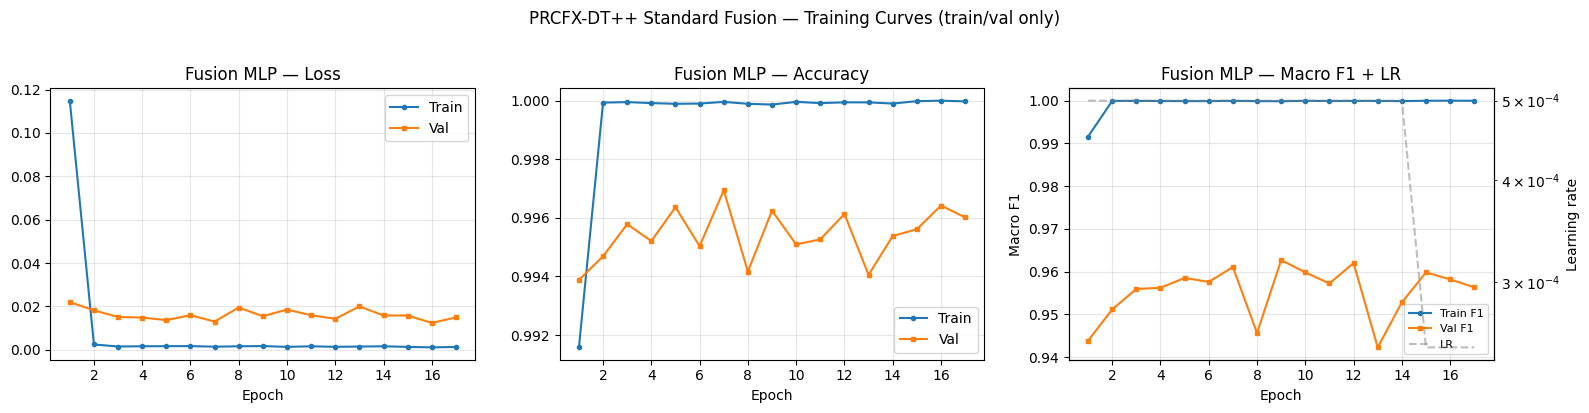


Training time statistics:
  Mean per epoch : 15.3 s
  Fastest epoch  : 13.6 s
  Slowest epoch  : 17.4 s


In [11]:
# Learning curves (train and val only)

history_df = pd.DataFrame(history)
display(history_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Loss
axes[0].plot(history_df['epoch'], history_df['train_loss'],
             marker='o', markersize=3, label='Train')
axes[0].plot(history_df['epoch'], history_df['val_loss'],
             marker='s', markersize=3, label='Val')
axes[0].set_title('Fusion MLP — Loss')
axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history_df['epoch'], history_df['train_acc'],
             marker='o', markersize=3, label='Train')
axes[1].plot(history_df['epoch'], history_df['val_acc'],
             marker='s', markersize=3, label='Val')
axes[1].set_title('Fusion MLP — Accuracy')
axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=0.3)

# Macro F1 + LR on twin axis
ax_f1 = axes[2]
ax_lr = ax_f1.twinx()
ax_f1.plot(history_df['epoch'], history_df['train_f1'],
           marker='o', markersize=3, color='tab:blue', label='Train F1')
ax_f1.plot(history_df['epoch'], history_df['val_f1'],
           marker='s', markersize=3, color='tab:orange', label='Val F1')
ax_lr.semilogy(history_df['epoch'], history_df['lr'],
               linestyle='--', color='tab:grey', alpha=0.5, label='LR')
ax_f1.set_title('Fusion MLP — Macro F1 + LR')
ax_f1.set_xlabel('Epoch')
ax_f1.set_ylabel('Macro F1'); ax_lr.set_ylabel('Learning rate')
lines1, labels1 = ax_f1.get_legend_handles_labels()
lines2, labels2 = ax_lr.get_legend_handles_labels()
ax_f1.legend(lines1 + lines2, labels1 + labels2, fontsize=8)
ax_f1.grid(alpha=0.3)

plt.suptitle('PRCFX-DT++ Standard Fusion — Training Curves (train/val only)', y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fusion_standard_val_training_curves.png', dpi=150)
plt.show()

print(f'\nTraining time statistics:')
print(f'  Mean per epoch : {history_df["epoch_time_s"].mean():.1f} s')
print(f'  Fastest epoch  : {history_df["epoch_time_s"].min():.1f} s')
print(f'  Slowest epoch  : {history_df["epoch_time_s"].max():.1f} s')

## 12 · Final evaluation on the test set  *(one-shot)*

In [12]:
# Final evaluation: best checkpoint, test set, once

fusion_model.load_state_dict(best_state_dict)

_, final_acc, final_f1, y_true, y_pred = evaluate(
    fusion_model, test_loader, criterion, DEVICE
)

print('=' * 60)
print('PRCFX-DT++ STANDARD FUSION — FINAL TEST RESULTS')
print('(best-val-F1 checkpoint; test set evaluated once)')
print('=' * 60)
print(f'  Test Accuracy : {final_acc:.4f}')
print(f'  Test Macro F1 : {final_f1:.4f}')
print()
print(classification_report(
    y_true, y_pred,
    target_names = class_names,
    digits       = 4,
    zero_division= 0,
))

PRCFX-DT++ STANDARD FUSION — FINAL TEST RESULTS
(best-val-F1 checkpoint; test set evaluated once)
  Test Accuracy : 0.9967
  Test Macro F1 : 0.9585

                 precision    recall  f1-score   support

         corona     0.9998    1.0000    0.9999     13012
 coxsackievirus     0.9890    0.9539    0.9711       282
  crimean-congo     1.0000    0.9655    0.9825        29
cytomegalovirus     0.9365    0.9516    0.9440        62
         dengue     0.9907    0.9950    0.9929      1609
          ebola     0.9885    0.9863    0.9874       437
   encephalitis     1.0000    0.6923    0.8182        26
            flu     0.9996    0.9997    0.9997     10635
    hepatitis b     1.0000    1.0000    1.0000      1678
    hepatitis c     1.0000    1.0000    1.0000       159
            hiv     0.9984    0.9995    0.9989      3671
          lassa     0.8667    1.0000    0.9286        52
        marburg     1.0000    0.9091    0.9524        11
 mastadenovirus     0.9647    0.9820    0.9733      

## 13 · Confusion matrix

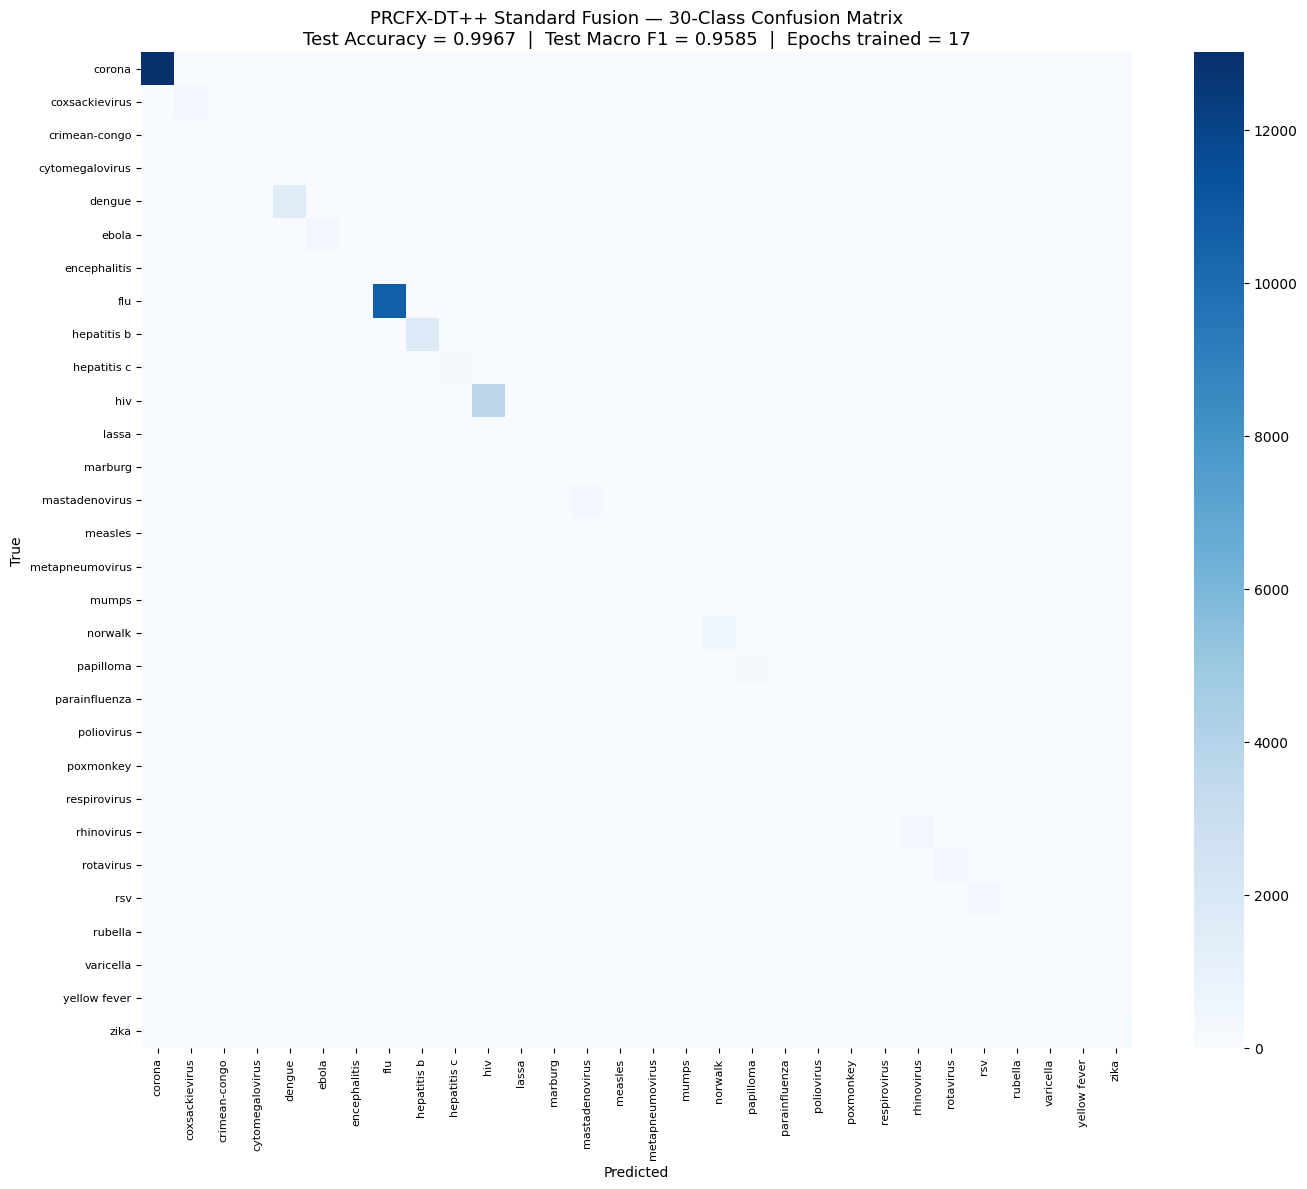

In [13]:
# 30-class confusion matrix

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, ax=ax, cmap='Blues', annot=False,
            xticklabels=class_names, yticklabels=class_names)
ax.set_title(
    f'PRCFX-DT++ Standard Fusion — 30-Class Confusion Matrix\n'
    f'Test Accuracy = {final_acc:.4f}  |  Test Macro F1 = {final_f1:.4f}  '
    f'|  Epochs trained = {len(history)}',
    fontsize=13
)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.tick_params(axis='x', rotation=90, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fusion_standard_val_confusion_matrix.png', dpi=150)
plt.show()

## 14 · Ablation comparison table

In [14]:
# Ablation comparison table
#
# Reads the Stream A and Stream B summaries and adds the fusion results.

rows = []

sa_sum = STREAM_A_DIR / 'stream_a_val_summary.csv'
if sa_sum.exists():
    sa = pd.read_csv(sa_sum).iloc[0]
    rows.append({
        'System'     : 'Stream A — CPNR-GASF-CNN',
        'Accuracy'   : sa.get('final_test_acc', float('nan')),
        'Macro F1'   : sa.get('final_test_macro_f1', float('nan')),
        'Checkpoint' : 'best val F1',
    })
else:
    print(f'WARNING: {sa_sum} not found — run the Stream A notebook first.')

sb_sum = STREAM_B_DIR / 'stream_b_summary.csv'
if sb_sum.exists():
    sb = pd.read_csv(sb_sum).iloc[0]
    rows.append({
        'System'     : 'Stream B — PRCFX-DT PageRank',
        'Accuracy'   : sb.get('test_acc', float('nan')),
        'Macro F1'   : sb.get('test_macro_f1', float('nan')),
        'Checkpoint' : 'best CV score (DT)',
    })
else:
    print(f'WARNING: {sb_sum} not found.')

rows.append({
    'System'     : 'Fusion — Standard MLP (A+B)',
    'Accuracy'   : round(float(final_acc), 4),
    'Macro F1'   : round(float(final_f1), 4),
    'Checkpoint' : 'best val F1',
})

ablation_df = pd.DataFrame(rows)
print('Ablation Study Results')
print('=' * 70)
display(ablation_df.to_string(index=False))

Ablation Study Results


'                      System  Accuracy  Macro F1         Checkpoint\n    Stream A — CPNR-GASF-CNN  0.975287  0.878983        best val F1\nStream B — PRCFX-DT PageRank  0.997575  0.982891 best CV score (DT)\n Fusion — Standard MLP (A+B)  0.996700  0.958500        best val F1'

## 15 · Save all artefacts

In [15]:
# Save all artefacts

history_df.to_csv(OUTPUT_DIR / 'fusion_standard_val_training_history.csv', index=False)
ablation_df.to_csv(OUTPUT_DIR / 'ablation_study_standard_val.csv', index=False)

joblib.dump(scaler_a, OUTPUT_DIR / 'scaler_a.joblib')
joblib.dump(scaler_b, OUTPUT_DIR / 'scaler_b.joblib')

torch.save({
    'model_state_dict'       : best_state_dict,
    'class_names'            : class_names,
    'num_classes'            : num_classes,
    'dim_a'                  : DIM_A,
    'dim_b'                  : DIM_B,
    'dim_joint'              : DIM_JOINT,
    'best_val_macro_f1'      : best_val_f1,
    'final_test_acc'         : final_acc,
    'final_test_macro_f1'    : final_f1,
    'epochs_trained'         : len(history),
    'total_train_time_s'     : total_secs,
}, OUTPUT_DIR / 'fusion_standard_val_model.pt')

summary = pd.DataFrame([{
    'system'                 : 'PRCFX-DT++ Standard Fusion',
    'fusion_type'            : 'Late concatenation MLP',
    'dim_a'                  : DIM_A,
    'dim_b'                  : DIM_B,
    'dim_joint'              : DIM_JOINT,
    'num_classes'            : num_classes,
    'n_train'                : len(y_train),
    'n_val'                  : len(y_val),
    'n_test'                 : len(y_test),
    'epochs_trained'         : len(history),
    'best_val_macro_f1'      : round(float(best_val_f1), 6),
    'final_test_acc'         : round(float(final_acc),   6),
    'final_test_macro_f1'    : round(float(final_f1),    6),
    'total_train_time_s'     : round(total_secs,          1),
    'total_train_time_hms'   : f'{total_h:02d}h {total_m:02d}m {total_s:04.1f}s',
}])
summary.to_csv(OUTPUT_DIR / 'fusion_standard_val_summary.csv', index=False)
display(summary.T)

print(f'\nAll artefacts saved to: {OUTPUT_DIR}')

,0
system,PRCFX-DT++ Standard Fusion
fusion_type,Late concatenation MLP
dim_a,256
dim_b,64
dim_joint,320
num_classes,30
n_train,121226
n_val,17319
n_test,34637
epochs_trained,17



All artefacts saved to: output_fusion_standard_val
